# The smell pathway: ORNs to Kenyon cells to MBONs

The olfactory pathway of the fly runs from the olfactory receptor neurons (`ORN_*`, 53 glomerular
types, one per antennal-lobe glomerulus) through the uniglomerular projection neurons
(`<glomerulus>_lPN`/`_adPN`/`_vPN`) to the Kenyon cells (`KC*`, the mushroom body's ~4,000-neuron
expansion layer) and on to the mushroom-body output neurons (`MBON*`, 36 types). In a real fly,
Kenyon-cell activity is famously **sparse**: in vivo, a single odor activates roughly **5-10% of
the Kenyon population** (Honegger, Campbell & Turner 2011, *Cell*; Turner, Bazhenov & Loesel 2008,
*J. Neurophysiol*).

This notebook builds odors as sets of ORN types, drives them at several strengths, and measures
what happens at each stage of that pathway in the model.

The answer is a **negative result**, and a clear one. It comes in three parts:

1. **The first relay works.** Injecting an ORN type drives its glomerular projection neurons hard
   (from their ~16 Hz rest rate to near the model's 50 Hz ceiling).
2. **The Kenyon-cell layer is saturated at rest.** In the model's calibrated configuration, about
   **4,063 of 4,064 Kenyon cells fire on every single step** with no odor at all. The repository's
   own `notebooks/reservoir.ipynb` records the same thing ("Kenyon cells active at a given step:
   100.0%" for the connectome), and gets chance-level (9.2%) digit readouts from Kenyon cells.
3. **So the smell signal vanishes at the Kenyon stage.** In seven of eight noise seeds, odor
   stimulation changes Kenyon-cell spiking by at most ~20 extra spikes across the whole population
   in a 1 s window (well under 0.1% of the Kenyon spike-slots), regardless of strength; the
   overlap between any two odors' Kenyon "patterns" is a Jaccard of ~1.0; and no MBON responds
   reliably. (The eighth seed sits on a tipping point -- see below.)

The model therefore does **not** reproduce the 5-10% sparse Kenyon code. We do not retune any
parameter to make it appear (the issue forbids tuning to hit the number); we show instead how the
result depends on input strength (it does not), and that the saturation is a property of the real
wiring: on a degree-preserving rewiring of the same model, resting Kenyon activity drops to
~26%.

**Before running:** `pip install flybrain matplotlib scipy`. The first `FlyBrain()` downloads the
brain (~260 MB) once. Everything runs on the CPU; the whole notebook takes about **6 minutes**.

**No claims about learning:** flybrain has no plasticity in the mushroom body; nothing here says
anything about odor learning, only about the feedforward sweep ORN -> PN -> KC -> MBON.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import platform

import flybrain
from flybrain import FlyBrain

# sensory_input=False removes every synapse ONTO sensory neurons. With the default True,
# ORN-to-ORN synapses pin the olfactory receptor neurons near their maximum rate at rest,
# so odours add nothing (see FlyBrain's docstring and README finding 4). The repository's
# olfactory work (notebooks/reservoir.ipynb) uses the same setting.
brain = FlyBrain(device="cpu", sensory_input=False)
ct = brain.cell_type.astype(str)

orn_types = sorted(np.unique(ct[np.char.startswith(ct, "ORN_")]))
kc = np.flatnonzero(np.char.startswith(ct, "KC"))
mbons = np.flatnonzero(np.char.startswith(ct, "MBON"))
print(f"flybrain {flybrain.__version__} on {platform.system()} ({platform.machine()}): "
      f"{brain.n:,} neurons; {len(orn_types)} ORN types, {len(kc)} Kenyon cells, "
      f"{len(np.unique(ct[mbons]))} MBON types ({len(mbons)} neurons)")

flybrain 0.1.1 on Darwin (arm64): 166,700 neurons; 53 ORN types, 4064 Kenyon cells, 36 MBON types (97 neurons)


## Odors

Three single glomeruli (`ORN_DM1`, `ORN_DL5`, `ORN_VA2`, each tens of receptor neurons on both
sides) and two seeded random mixtures (4 and 10 glomeruli). A 2 s trial (100 steps of 20 ms) with
the odor on for the middle 1 s; the injected voltage is added to every ORN of the chosen types at
every step while on. Four strengths: 0.1, 0.5, 1.0, 2.0 V per step. Eight noise seeds per
condition, and a matched-noise blank run per seed (same noise, no odor) so every "extra" below is
odor minus blank, not odor minus nothing.

For each odor we also name its **projection neurons** (`<glomerulus>_lPN` / `_adPN` / `_vPN`) --
the uniglomerular cells that in a real fly copy one glomerulus' ORN input to the mushroom body and
lateral horn.

In [2]:
rng = np.random.default_rng(7)
others = [t for t in orn_types if t not in ("ORN_DM1", "ORN_DL5", "ORN_VA2")]
mix4 = [others[i] for i in rng.permutation(len(others))[:4]]
mix10 = [others[i] for i in rng.permutation(len(others))[:10]]
ODORS = {"DM1": ["ORN_DM1"], "DL5": ["ORN_DL5"], "VA2": ["ORN_VA2"], "mix4": mix4, "mix10": mix10}
STRENGTHS = [0.1, 0.5, 1.0, 2.0]
SEEDS = list(range(8))
T, ON, TAIL = 100, (25, 75), 5          # odor on for 1 s; +5 steps of tail for propagation


def pns_for(types):
    '''Uniglomerular projection neurons of a mixture's glomeruli.'''
    names = [t.removeprefix("ORN_") for t in types]
    return brain.cells([f"{g}_{s}" for g in names for s in ("lPN", "adPN", "vPN")])


def slot_of(idx):
    s = np.full(brain.n, -1, np.int64)
    s[idx] = np.arange(len(idx))
    return s


kc_slot, mbon_slot = slot_of(kc), slot_of(mbons)
mbon_ct = ct[mbons]

for name, types in ODORS.items():
    idx, pn = brain.cells(types), pns_for(types)
    print(f"{name:6s}: {len(types):2d} ORN types ({len(idx):3d} neurons) -> {len(pn):2d} uniglomerular PNs")


def trial(seed, idx, amount, pn_idx=None):
    '''One 2 s run. Per-step firing fractions over the window + tail for the
    injected ORNs, their PNs and the Kenyon cells; spike counts for all neurons.'''
    brain.reset(seed)
    pn_idx = np.asarray(pn_idx if pn_idx is not None else [])
    orn_slot = slot_of(idx) if len(idx) else None
    pn_slot = slot_of(pn_idx) if len(pn_idx) else None
    out = {k: np.zeros(ON[1] - ON[0] + TAIL) for k in ("orn", "pn", "kc")}
    kc_counts = np.zeros(brain.n, np.int32)
    mbon_counts = np.zeros(brain.n, np.int32)
    i = 0
    for t in range(T):
        fired = brain.step(inject=[(idx, amount)] if ON[0] <= t < ON[1] else ())
        if ON[0] <= t < ON[1] + TAIL:
            if len(fired):
                if orn_slot is not None:
                    h = orn_slot[fired]; out["orn"][i] = (h >= 0).sum() / len(idx)
                if pn_slot is not None:
                    h = pn_slot[fired]; out["pn"][i] = (h >= 0).sum() / max(1, len(pn_idx))
                h = kc_slot[fired]; out["kc"][i] = (h >= 0).sum() / len(kc)
                kc_counts[fired] += 1
                mbon_counts[fired] += 1
            i += 1
    return out, kc_counts, mbon_counts

DM1   :  1 ORN types ( 74 neurons) ->  2 uniglomerular PNs
DL5   :  1 ORN types ( 43 neurons) ->  2 uniglomerular PNs
VA2   :  1 ORN types ( 83 neurons) ->  2 uniglomerular PNs
mix4  :  4 ORN types (252 neurons) -> 16 uniglomerular PNs


mix10 : 10 ORN types (436 neurons) -> 43 uniglomerular PNs


## First, the resting state

Before any odor: how active is each stage? (This is the fact the whole result turns on, so we
measure it first.)

In [3]:
rest = {}
for seed in SEEDS:
    rest[seed] = trial(seed, np.empty(0, np.int64), 0.0)
kc_frac = np.array([rest[s][0]["kc"] for s in SEEDS])
for seed in SEEDS:
    print(f"  seed {seed}: Kenyon cells firing per step at rest {100 * kc_frac[SEEDS.index(seed)].mean():.2f}%")
print(f"median seed: {100 * np.median(kc_frac):.2f}% of {len(kc)} Kenyon cells fire every step")
spikes = [len(brain.step()) for _ in range(20)]
print(f"whole-brain spikes per step at rest: ~{np.mean(spikes):.0f}")

  seed 0: Kenyon cells firing per step at rest 99.97%
  seed 1: Kenyon cells firing per step at rest 99.97%
  seed 2: Kenyon cells firing per step at rest 99.97%
  seed 3: Kenyon cells firing per step at rest 99.97%
  seed 4: Kenyon cells firing per step at rest 93.02%
  seed 5: Kenyon cells firing per step at rest 99.97%
  seed 6: Kenyon cells firing per step at rest 99.97%
  seed 7: Kenyon cells firing per step at rest 99.60%
median seed: 99.98% of 4064 Kenyon cells fire every step
whole-brain spikes per step at rest: ~7605


## Run the odor sweep

In [4]:
t0 = time.time()
res, blank, pn_of = {}, {}, {}
for name, types in ODORS.items():
    idx = brain.cells(types)
    pn_of[name] = pns_for(types)
    for a in STRENGTHS:
        for seed in SEEDS:
            res[name, a, seed] = trial(seed, idx, a, pn_of[name])
for seed in SEEDS:
    blank[seed] = trial(seed, np.empty(0, np.int64), 0.0)
print(f"{len(res) + len(blank)} runs in {(time.time() - t0) / 60:.1f} min")

168 runs in 1.6 min


## The first relay works: projection neurons

Injected ORNs fire at the ceiling during the odor window, and their uniglomerular projection
neurons follow: from a ~0.3 per-step rest rate (about 16 Hz, matching the README's measured DM1/DM2
rest rate) to near one spike per step (~50 Hz, the model ceiling) at 0.5 V and above. The signal
crosses ORN -> PN cleanly, on the odor's own glomeruli.

In [5]:
print(f"{'odor':6s} {'V/step':>6s} {'ORN fired/step':>14s} {'PN fired/step':>14s}")
for name in ODORS:
    for a in STRENGTHS:
        orn = np.mean([res[name, a, s][0]["orn"].mean() for s in SEEDS])
        pn = np.mean([res[name, a, s][0]["pn"].mean() for s in SEEDS])
        print(f"{name:6s} {a:6.1f} {orn:14.2f} {pn:14.2f}")
pn_blank = np.mean([np.mean([blank[s][0]["pn"].mean()]) for s in SEEDS])
print(f"{'blank':6s} {0.0:6.1f} {'--':>14s} {pn_blank:14.2f}")

odor   V/step ORN fired/step  PN fired/step
DM1       0.1           0.12           0.43
DM1       0.5           0.45           0.48
DM1       1.0           0.91           0.93
DM1       2.0           0.91           0.93
DL5       0.1           0.12           0.44
DL5       0.5           0.45           0.48
DL5       1.0           0.91           0.93
DL5       2.0           0.91           0.93
VA2       0.1           0.12           0.37
VA2       0.5           0.45           0.48
VA2       1.0           0.91           0.93
VA2       2.0           0.91           0.93
mix4      0.1           0.12           0.38
mix4      0.5           0.45           0.50
mix4      1.0           0.91           0.93
mix4      2.0           0.91           0.93
mix10     0.1           0.12           0.40
mix10     0.5           0.45           0.48
mix10     1.0           0.91           0.92
mix10     2.0           0.91           0.92
blank     0.0             --           0.00


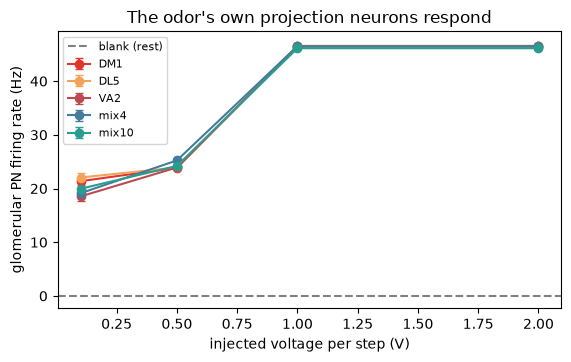

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, color in zip(ODORS, ("#e0342c", "#f4a259", "#bc4b51", "#457b9d", "#2a9d8f")):
    pn = [np.mean([res[name, a, s][0]["pn"].mean() for s in SEEDS]) * 50 for a in STRENGTHS]
    sd = [np.std([res[name, a, s][0]["pn"].mean() for s in SEEDS], ddof=1) * 50 for a in STRENGTHS]
    ax.errorbar(STRENGTHS, pn, yerr=sd, marker="o", capsize=3, color=color, label=name)
ax.axhline(pn_blank * 50, ls="--", c="0.5", label="blank (rest)")
ax.set_xlabel("injected voltage per step (V)")
ax.set_ylabel("glomerular PN firing rate (Hz)")
ax.set_title("The odor's own projection neurons respond")
ax.legend(fontsize=8)
plt.show()

## The Kenyon layer: saturated, so the odor adds nothing

Now the measurement the issue asks for: **the fraction of Kenyon cells that spike**. Over a whole
1 s window the answer is ~100% for every odor, every strength, every seed -- but it is also ~100%
for the blank. Kenyon cells at rest fire every step in this configuration, so "fraction that
spikes" cannot separate an odor from no odor. The informative number is the **odor-attributable**
spiking: Kenyon spikes in the stimulus run minus the matched-noise blank run, per seed.

For **seven of the eight seeds that number is effectively zero at every strength**: per-seed
extras of -11 to +21 spikes (medians -2 to +16) in a window that contains ~220,000 Kenyon
spike-slots (4,064 neurons x 55 steps) -- well under 0.1% of Kenyon cells gain even one spike.
**One seed sits on a tipping point instead**: in that noise trajectory the blank run's Kenyon
layer settles at ~93% per step rather than ~100%, and the odor tips it over (up to ~1,555 extra
spikes; the `max` column below). The layer is metastable between nearly-saturated regimes, not
stably sparse. In the in-vivo literature, 5-10% of Kenyon cells *respond* to an odor; here the
typical seed shows **at most a few hundredths of a percent gaining a spike**, and the population
is ~100% active before the odor arrives.

In [7]:
print(f"{'odor':6s} {'V/step':>6s} {'extra KC spikes, per seed':>34s} {'median':>7s} {'max':>6s}")
for name in ODORS:
    for a in STRENGTHS:
        extra = np.stack([res[name, a, s][1][kc] - blank[s][1][kc] for s in SEEDS])
        tot = extra.sum(1)
        print(f"{name:6s} {a:6.1f} {str(tot.tolist()):>34s} {np.median(tot):7.0f} {tot.max():6.0f}")

odor   V/step          extra KC spikes, per seed  median    max


DM1       0.1     [5, -2, 3, 13, 376, 6, -4, -1]       4    376
DM1       0.5         [4, 1, 4, 3, 918, 4, 1, 7]       4    918
DM1       1.0 [11, 13, 14, 20, 1555, 21, 15, 12]      14   1555
DM1       2.0 [11, 13, 14, 20, 1555, 21, 15, 12]      14   1555
DL5       0.1    [-3, -3, -7, 4, 133, -1, 1, -2]      -2    133
DL5       0.5     [-3, -3, -1, 4, 550, 4, 2, -7]       0    550
DL5       1.0  [-1, -2, 10, 13, 792, -1, -2, -2]      -1    792
DL5       2.0  [-1, -2, 10, 13, 792, -1, -2, -2]      -1    792
VA2       0.1      [2, -11, 1, 6, 304, 9, 6, -2]       4    304
VA2       0.5      [3, 3, 3, 10, 722, 12, -4, 1]       3    722
VA2       1.0  [24, 18, 12, 17, 1039, 16, 6, 10]      16   1039
VA2       2.0  [24, 18, 12, 17, 1039, 16, 6, 10]      16   1039
mix4      0.1       [4, 1, -2, 9, 435, 9, 1, -2]       2    435
mix4      0.5    [-5, -3, -4, 6, 860, 5, -2, -5]      -2    860
mix4      1.0     [4, 3, 10, 14, 1478, 6, 8, -6]       7   1478
mix4      2.0     [4, 3, 10, 14, 1478, 6

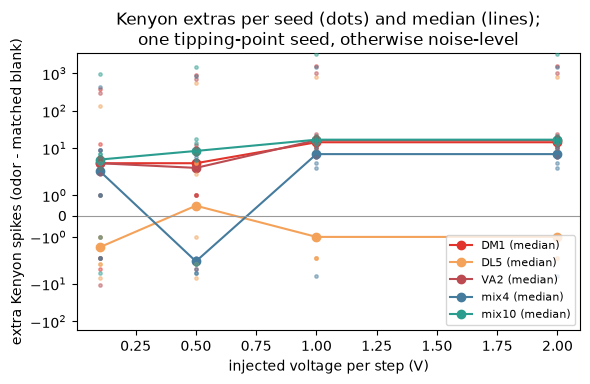

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, color in zip(ODORS, ("#e0342c", "#f4a259", "#bc4b51", "#457b9d", "#2a9d8f")):
    tot = np.stack([np.stack([res[name, a, s][1][kc] - blank[s][1][kc] for s in SEEDS]).sum(1)
                    for a in STRENGTHS])          # (strength, seed)
    ax.plot(STRENGTHS, np.median(tot, 1), marker="o", color=color, label=f"{name} (median)")
    ax.scatter(np.repeat(STRENGTHS, len(SEEDS)), tot.ravel(), s=6, color=color, alpha=0.45,
               zorder=3)
ax.axhline(0, c="0.6", lw=0.8)
ax.set_yscale("symlog")
ax.set_xlabel("injected voltage per step (V)")
ax.set_ylabel("extra Kenyon spikes (odor - matched blank)")
ax.set_title("Kenyon extras per seed (dots) and median (lines);\none tipping-point seed, otherwise noise-level")
ax.legend(fontsize=8)
plt.show()

### Overlap between odors

Two different odors should activate different Kenyon subsets; in vivo their patterns overlap only
weakly. Here the "pattern" of every odor is the same ~all-Kenyon set the blank produces, so the
Jaccard overlap of any two odors' Kenyon spike sets is ~1.0 -- the set contains no odor
information at all.

In [9]:
names = list(ODORS)
print(f"Jaccard overlap of Kenyon spike sets at 1.0 V (mean over {len(SEEDS)} seeds):")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        ov = []
        for s in SEEDS:
            a = res[names[i], 1.0, s][1][kc] > 0
            b = res[names[j], 1.0, s][1][kc] > 0
            union = (a | b).sum()
            ov.append((a & b).sum() / union if union else np.nan)
        print(f"  {names[i]:6s} vs {names[j]:6s}: {np.mean(ov):.3f}")

Jaccard overlap of Kenyon spike sets at 1.0 V (mean over 8 seeds):
  DM1    vs DL5   : 1.000
  DM1    vs VA2   : 1.000
  DM1    vs mix4  : 1.000
  DM1    vs mix10 : 1.000
  DL5    vs VA2   : 1.000
  DL5    vs mix4  : 1.000
  DL5    vs mix10 : 1.000
  VA2    vs mix4  : 1.000
  VA2    vs mix10 : 1.000
  mix4   vs mix10 : 1.000


## MBONs: no reliable response

Mushroom-body output neurons receive the Kenyon cells -- and at rest they are **also nearly
saturated** (about 91% of MBON spike-slots are used before any odor). With both the input layer
and the readout pinned at the ceiling, no MBON can respond to any odor: per-seed medians hover
around zero, and the only large values come from the same tipping-point seed (a real fly's MBONs
respond to an odor in tens of spikes per second, from a quiet baseline).

In [10]:
blank_mbon = np.stack([blank[s][2][mbons] for s in SEEDS])
print(f"MBON spikes at rest: {blank_mbon.sum(1).mean():.0f} over the window across {len(mbons)} "
      f"neurons = {100 * blank_mbon.sum(1).mean() / (len(mbons) * 55):.0f}% of MBON spike-slots")
print("\nStrongest MBON response per odor at 1.0 V (extra spikes, per-seed median / max):")
for name in ODORS:
    extra = np.stack([res[name, 1.0, s][2][mbons] - blank[s][2][mbons] for s in SEEDS])
    i = np.argmax(np.median(extra, 0))
    print(f"  {name:6s}: {mbon_ct[i]:>8s} median {np.median(extra[:, i]):+.1f}, max {extra[:, i].max():+.1f} "
          f"(positive in {(extra[:, i] > 0).sum()}/{len(SEEDS)} seeds)")

MBON spikes at rest: 4853 over the window across 97 neurons = 91% of MBON spike-slots

Strongest MBON response per odor at 1.0 V (extra spikes, per-seed median / max):
  DM1   :   MBON10 median +2.0, max +3.0 (positive in 7/8 seeds)
  DL5   :   MBON10 median +0.5, max +4.0 (positive in 4/8 seeds)
  VA2   :   MBON10 median +2.5, max +5.0 (positive in 7/8 seeds)
  mix4  :   MBON20 median +1.0, max +2.0 (positive in 6/8 seeds)
  mix10 :   MBON15 median +1.0, max +3.0 (positive in 5/8 seeds)


## Is the saturation the wiring's fault?

The Kenyon cells being pinned at the ceiling is a property of the **real connectome's** recurrent
drive in this model recipe, not of the recipe alone: the repository's `notebooks/reservoir.ipynb`
records Kenyon activity of 100% for the connectome but only 18-27% for random rewirings of the
same model. We reproduce that control here (degree-preserving rewiring: every neuron keeps its
in- and out-degree and its synaptic signs; who connects to whom is random, and incoming weight
strengths are rescaled to match) -- resting Kenyon activity collapses when the wiring is
scrambled. Whatever the mechanism, it lives in the real wiring.

(Swapping the weight matrix uses `FlyBrain`'s internal arrays, exactly as `reservoir.ipynb` does;
it is a notebook trick, not a public API.)

resting Kenyon cells firing per step: connectome 100.0% ± 0.0, degree-preserving rewiring 5.0% ± 0.1


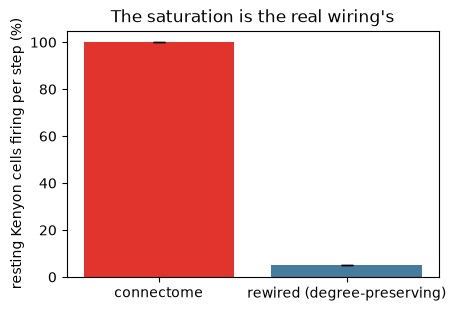

In [11]:
from scipy import sparse

original = sparse.csc_matrix((brain.weights, brain.indices, brain.indptr), shape=(brain.n, brain.n)).tocsr()
row_strength = np.asarray(abs(original).sum(1)).ravel()


def match_input_strength(W):
    W = W.tocsr()
    W.sum_duplicates()
    s = np.asarray(abs(W).sum(1)).ravel()
    scale = np.divide(row_strength, s, out=np.zeros_like(s), where=s > 0)
    W = sparse.diags(scale.astype(np.float32)) @ W
    W.eliminate_zeros()
    return W.tocsr()


coo = original.tocoo()
post = np.random.default_rng(11).permutation(coo.row)
shuffled = match_input_strength(sparse.coo_matrix((coo.data, (post, coo.col)), shape=original.shape))


def use_weights(W):
    W = W.tocsr().astype(np.float32)
    W.sort_indices()
    csc = W.tocsc()
    brain.indptr, brain.indices, brain.weights = csc.indptr, csc.indices, csc.data


def rest_kc_fraction(seeds, settle=25, steps=30):
    '''The same window the sweep uses: settle for 25 steps, then measure.'''
    fr = []
    for seed in seeds:
        brain.reset(seed)
        for _ in range(settle):
            brain.step()
        c = 0
        for _ in range(steps):
            fired = brain.step()
            c += (kc_slot[fired] >= 0).sum() if len(fired) else 0
        fr.append(c / (steps * len(kc)))
    return np.array(fr)


frac_real = rest_kc_fraction(SEEDS[:4])
use_weights(shuffled)
frac_shuffled = rest_kc_fraction(SEEDS[:4])
use_weights(original)
print(f"resting Kenyon cells firing per step: connectome {100 * frac_real.mean():.1f}% "
      f"± {100 * frac_real.std(ddof=1):.1f}, degree-preserving rewiring {100 * frac_shuffled.mean():.1f}% "
      f"± {100 * frac_shuffled.std(ddof=1):.1f}")

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar([0, 1], [100 * frac_real.mean(), 100 * frac_shuffled.mean()],
       yerr=[100 * frac_real.std(ddof=1), 100 * frac_shuffled.std(ddof=1)], capsize=4,
       color=["#e0342c", "#457b9d"])
ax.set_xticks([0, 1], ["connectome", "rewired (degree-preserving)"])
ax.set_ylabel("resting Kenyon cells firing per step (%)")
ax.set_title("The saturation is the real wiring's")
plt.show()

## What the ORN-to-ORN runaway would have added

With `sensory_input=True` (the default), the ORN-to-ORN synapses pin the receptor neurons near
their maximum rate at rest, so odors add nothing even at the *input* stage (README finding 4). We
verify that quickly here, then continue with the `sensory_input=False` brain used above:

In [12]:
brain2 = FlyBrain(device="cpu", sensory_input=True)
ct2 = brain2.cell_type.astype(str)
orn_all = np.flatnonzero(np.char.startswith(ct2, "ORN_"))
orn_slot2 = np.full(brain2.n, -1, np.int64)
orn_slot2[orn_all] = np.arange(len(orn_all))
brain2.reset(0)
for _ in range(10):
    brain2.step()
c = 0
for _ in range(30):
    fired = brain2.step()
    c += (orn_slot2[fired] >= 0).sum() if len(fired) else 0
print(f"ORN firing per step with sensory_input=True: {100 * c / (30 * len(orn_all)):.0f}% "
      f"(pinned by ORN-to-ORN synapses; see README finding 4)")
del brain2

ORN firing per step with sensory_input=True: 50% (pinned by ORN-to-ORN synapses; see README finding 4)


## Summary

* **Fraction of Kenyon cells that spike: ~100%, for every odor, every strength (0.1-2.0 V/step),
  and with no odor at all.** The Kenyon layer of this model sits at (or a whisker from) the 50 Hz
  ceiling at rest, so the sparseness measure cannot even in principle separate odors. One seed in
  eight settles at ~93% instead of ~100% -- the layer is metastable between near-saturated
  regimes, and the only sizable odor effect in the whole notebook is that seed tipping over.
* **Odor-attributable Kenyon spiking: noise-level** -- per-seed extras of -11 to +21 spikes
  (medians -2 to +16) across 4,064 neurons in a 1 s window, with no growth in input strength. The
  in-vivo literature reports 5-10% of Kenyon cells responding to an odor (Honegger et al. 2011;
  Turner et al. 2008): on typical seeds the model fails this comparison by two to three orders of
  magnitude, in the direction of total saturation. The exception is the tipping-point seed, where
  the odor knocks a metastable ~93%-active layer to ~94% -- a bifurcation, not an olfactory code.
* **Pattern overlap between odors: Jaccard ~1.0 for every pair** -- there is no pattern
  structure to overlap.
* **MBONs do not respond reliably to any odor**: they are ~91% saturated at rest, so the layer
  has no dynamic range.
* **The signal does cross the first relay**: injected ORNs drive their glomerular projection
  neurons from ~16 Hz to near the 50 Hz ceiling. The failure starts at the PN -> Kenyon stage.
* **The saturation is specific to the real wiring**: a degree-preserving rewiring of the same
  model runs its Kenyon layer far quieter at rest (matching the repository's reservoir notebook,
  which also found chance-level Kenyon readouts on the connectome and better readouts on random
  wirings).

**No parameter was retuned** to try to recover a sparse code (the issue forbids it); the result
is reported at the repository's own calibrated settings (tonic 0.14, gain 3.0; see
`FlyBrain`'s docstring).

## What the model leaves out

* **No plasticity, no learning claims.** The mushroom body here is a fixed relay; nothing in this
  notebook bears on odor learning, which is the mushroom body's best-known job.
* **No graded synaptic transmission.** Real Kenyon cells receive small, largely subthreshold
  inputs; a 20 ms-step LIF model with normalized weights and gain 3.0 sums whole-population
  volleys instead. The calibration that keeps descending neurons quiet at rest (README finding 3)
  leaves the Kenyon layer saturated.
* **Injection, not an odor plume.** The "odor" is voltage added directly to ORN types at a
  uniform rate; real odors arrive as temporally structured concentration transients across many
  glomeruli.
* **A single fixed weight gain** for every synapse class, no short-term dynamics, 20 ms time
  steps, and 8 noise seeds -- probabilities are over model noise, not over flies.